In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import rioxarray as rxr
import rasterio
from rasterio.plot import show
import matplotlib.pyplot as plt

### Loading all Saved Environmental Rasters 

In [2]:
dem = rxr.open_rasterio("data_processed/dem_1km_res.tif").squeeze()
dem = dem.where(dem != -32768)   # crs projection of master grid our dem is 4326

slope = rxr.open_rasterio("data_processed/slope.tif").squeeze() #crs projection is 3857

aspect = rxr.open_rasterio("data_processed/aspect.tif").squeeze() #crs projection is 3857

tern_rgd = rxr.open_rasterio("data_processed/tri.tif").squeeze() # terrain ruggedness crs projection is 3857

temp = rxr.open_rasterio("data_processed/breeding_temp_1km.tif").squeeze() # crs projection is 4326


In [3]:
# check alignment of shape
print(dem.shape)
print(slope.shape)
print(aspect.shape)
print(tern_rgd.shape)
print(temp.shape)

(301, 801)
(410, 751)
(410, 751)
(410, 751)
(301, 801)


In [4]:
# We reproject required rasters to match our DEM raster
slope = slope.rio.reproject_match(dem)
aspect = aspect.rio.reproject_match(dem)
aspect

<xarray.DataArray (y: 301, x: 801)> Size: 964kB
array([[      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan, 211.32869, 208.41266, ...,  88.8876 ,       nan,
              nan],
       [      nan, 219.80557, 237.65256, ..., 117.52522,       nan,
              nan],
       ...,
       [      nan, 356.63354, 298.61047, ...,  -1.     ,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan]], dtype=float32)
Coordinates:
    band         int32 4B 1
    spatial_ref  int32 4B 0
  * x            (x) float64 6kB 5.005 5.015 5.025 5.035 ... 12.98 12.99 13.0
  * y            (y) float64 2kB 48.0 47.99 47.98 47.97 ... 45.02 45.01 45.0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      aspect
    _FillValue:     -32768.0

In [5]:
print(float(dem.min()), float(dem.max()))
print(float(temp.min()), float(temp.max()))
print(float(slope.min()), float(slope.max()))
print(float(aspect.min()), float(aspect.max()))
print(float(tern_rgd.min()), float(tern_rgd.max()))

-8.0 4599.0
3.118363618850708 23.23716163635254
0.0 36.384098052978516
-1.0 359.9825439453125
0.0 978.7777709960938


In [6]:
# Check for NaNs and change them 0
print("DEM NaNs:", int(np.isnan(dem.values).sum()))
print("TEMP NaNs:", int(np.isnan(temp.values).sum()))
print("SLOPE NaNs:", int(np.isnan(slope.values).sum()))
print("Terrain Ruggedness NaNs:", int(np.isnan(tern_rgd.values).sum()))

DEM NaNs: 1101
TEMP NaNs: 4556
SLOPE NaNs: 3297
Terrain Ruggedness NaNs: 2318


### We got the NDVI Tif for Alps region for a select year 2022 

Bands: 1
Width: 669, Height: 339
CRS: EPSG:4326
Bounds: BoundingBox(left=4.99463297970454, bottom=44.996612581546835, right=11.004362230464139, top=48.04190139471201)


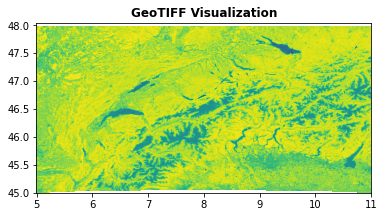

In [7]:
# The Alps GEOTIFF File from Sentinel 2 Harmonized Sat Data
with rasterio.open('data_processed/NDVI_Swiss_Alps.tif') as src:
    # 1. Check Metadata
    print(f"Bands: {src.count}")
    print(f"Width: {src.width}, Height: {src.height}")
    print(f"CRS: {src.crs}")
    print(f"Bounds: {src.bounds}")
    
    # 2. Read Pixel Data (1st band)
    data = src.read(1)
    
    # 3. Visualize for quick check
    show(src, title="GeoTIFF Visualization")

In [8]:
# Now the dimensions are different so we reproject to match our master grid DEM model
ndvi_alps = rxr.open_rasterio("data_processed/NDVI_Swiss_Alps.tif").squeeze()

print("Original Seninel 2A Shape:",ndvi_alps.shape)

ndvi_alps = ndvi_alps.rio.reproject_match(dem)

print("New Shape:", ndvi_alps.shape)

Original Seninel 2A Shape: (339, 669)
New Shape: (301, 801)


In [50]:
# Saving updated files

dem = dem.fillna(-9999)
slope = slope.fillna(-9999)
aspect = aspect.fillna(-9999)
temp = temp.fillna(-9999)
ndvi_alps = ndvi_alps.fillna(-9999)

dem.rio.to_raster("env_layers/elev.asc")
slope.rio.to_raster("env_layers/slope.asc")
aspect.rio.to_raster("env_layers/aspect.asc")
temp.rio.to_raster("env_layers/temp.asc")
ndvi_alps.rio.to_raster("env_layers/ndvi.asc")

C:\Users\91702\anaconda3\lib\site-packages\rioxarray\raster_writer.py:130: UserWarning: The nodata value (3.402823466e+38) has been automatically changed to (3.4028234663852886e+38) to match the dtype of the data.
  warnings.warn(


### We include now Occurence data for Rock Ptarmigan at the Alps

In [9]:
df = pd.read_csv("data_processed/Rock_Ptarmigan_Occrnc.csv", sep="\t") #occurence data from www.gbif.org
pd.set_option('display.max_columns', None)
df.head()

,gbifID,datasetKey,occurrenceID,kingdom,phylum,class,order,family,genus,species,infraspecificEpithet,taxonRank,scientificName,verbatimScientificName,verbatimScientificNameAuthorship,countryCode,locality,stateProvince,occurrenceStatus,individualCount,publishingOrgKey,decimalLatitude,decimalLongitude,coordinateUncertaintyInMeters,coordinatePrecision,elevation,elevationAccuracy,depth,depthAccuracy,eventDate,day,month,year,taxonKey,speciesKey,basisOfRecord,institutionCode,collectionCode,catalogNumber,recordNumber,identifiedBy,dateIdentified,license,rightsHolder,recordedBy,typeStatus,establishmentMeans,lastInterpreted,mediaType,issue
0,6183598936,8a863029-f435-446a-821e-275f4f641165,https://observation.org/observation/362525045,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Wallis (VS),Wallis (VS),PRESENT,2.0,c8d737e0-2ff8-42e8-b8fc-6b805d26fc5f,46.028279,7.455767,11.0,NaN,NaN,NaN,NaN,NaN,2025-07-11,11.0,7.0,2025.0,5227679,5227679,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,CC_BY_NC_4_0,Stichting Observation International,User 252570,NaN,NaN,2026-03-31T20:39:56.585Z,NaN,NaN
1,6183463547,8a863029-f435-446a-821e-275f4f641165,https://observation.org/observation/362490277,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Wallis (VS),Wallis (VS),PRESENT,2.0,c8d737e0-2ff8-42e8-b8fc-6b805d26fc5f,46.028358,7.455630,1.0,NaN,NaN,NaN,NaN,NaN,2025-07-11,11.0,7.0,2025.0,5227679,5227679,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,CC_BY_NC_4_0,Stichting Observation International,User 924943,NaN,NaN,2026-03-31T20:12:32.294Z,NaN,NaN
2,6182988400,8a863029-f435-446a-821e-275f4f641165,https://observation.org/observation/359776670,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Wallis (VS),Wallis (VS),PRESENT,1.0,c8d737e0-2ff8-42e8-b8fc-6b805d26fc5f,46.579033,8.390598,1.0,NaN,NaN,NaN,NaN,NaN,2025-06-29,29.0,6.0,2025.0,5227679,5227679,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,CC_BY_NC_4_0,Stichting Observation International,User 69441,NaN,NaN,2026-03-31T20:25:20.121Z,NaN,NaN
3,6182580136,8a863029-f435-446a-821e-275f4f641165,https://observation.org/observation/369680839,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Zernez (Gemeinde),Graubünden (GR),PRESENT,5.0,c8d737e0-2ff8-42e8-b8fc-6b805d26fc5f,46.725304,9.970130,2.0,NaN,NaN,NaN,NaN,NaN,2025-08-12,12.0,8.0,2025.0,5227679,5227679,HUMAN_OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,CC_BY_NC_4_0,Stichting Observation International,User 59638,NaN,NaN,2026-03-31T20:13:07.078Z,NaN,NaN
4,6181737025,6ac3f774-d9fb-4796-b3e9-92bf6c81c084,NaN,Animalia,Chordata,Aves,Galliformes,Phasianidae,Lagopus,Lagopus muta,NaN,SPECIES,"Lagopus muta (Montin, 1781)",Lagopus muta,NaN,CH,Safiental-oberes,NaN,PRESENT,NaN,bb646dff-a905-4403-a49b-6d378c2cf0d9,46.621277,9.256653,25.0,NaN,NaN,NaN,NaN,NaN,2026-03-21T00:00,21.0,3.0,2026.0,5227679,5227679,HUMAN_OBSERVATION,NABU|naturgucker,NABU|naturgucker,773708303,NaN,NaN,NaN,CC_BY_4_0,NaN,1593068209,NaN,NaN,2026-04-03T03:11:35.934Z,NaN,COORDINATE_ROUNDED;GEODETIC_DATUM_ASSUMED_WGS8...


In [10]:
# So we have lot of columns we don't need yet so we keep only coordinates, species and year and basis of obsvn for one's
# reference and drop the rest and clean the retained columns
df = df[["species", "locality","decimalLatitude", "decimalLongitude", "year", "basisOfRecord"]]
df

,species,locality,decimalLatitude,decimalLongitude,year,basisOfRecord
0,Lagopus muta,Wallis (VS),46.028279,7.455767,2025.0,HUMAN_OBSERVATION
1,Lagopus muta,Wallis (VS),46.028358,7.455630,2025.0,HUMAN_OBSERVATION
2,Lagopus muta,Wallis (VS),46.579033,8.390598,2025.0,HUMAN_OBSERVATION
3,Lagopus muta,Zernez (Gemeinde),46.725304,9.970130,2025.0,HUMAN_OBSERVATION
4,Lagopus muta,Safiental-oberes,46.621277,9.256653,2026.0,HUMAN_OBSERVATION
...,...,...,...,...,...,...
895,Lagopus muta,Valais,46.270000,7.740000,2006.0,HUMAN_OBSERVATION
896,Lagopus muta,Switzerland- Wallis,46.160126,7.367123,2012.0,HUMAN_OBSERVATION
897,Lagopus muta,Graubünden (GR),46.877577,9.266311,2012.0,HUMAN_OBSERVATION
898,Lagopus muta,Graubünden (GR),46.589541,8.685098,2011.0,HUMAN_OBSERVATION


In [11]:
# filter NaN/null values only on location data 
df = df.dropna(subset=["decimalLatitude", "decimalLongitude"])
df = df.drop_duplicates(subset=["decimalLatitude","decimalLongitude"]) # drop duplicates in coordinates

print(df.shape)
df.head()

(846, 6)


,species,locality,decimalLatitude,decimalLongitude,year,basisOfRecord
0,Lagopus muta,Wallis (VS),46.028279,7.455767,2025.0,HUMAN_OBSERVATION
1,Lagopus muta,Wallis (VS),46.028358,7.455630,2025.0,HUMAN_OBSERVATION
2,Lagopus muta,Wallis (VS),46.579033,8.390598,2025.0,HUMAN_OBSERVATION
3,Lagopus muta,Zernez (Gemeinde),46.725304,9.970130,2025.0,HUMAN_OBSERVATION
4,Lagopus muta,Safiental-oberes,46.621277,9.256653,2026.0,HUMAN_OBSERVATION


In [51]:
maxent_df = df[["species", "decimalLongitude", "decimalLatitude"]].copy()
maxent_df.columns = ["species", "longitude", "latitude"]
maxent_df.to_csv("maxent_occurrence.csv", index=False)

In [12]:
# We now involve the occurence data to match with the geo_terrain rasters
# Convert to GeoDataFrame
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.decimalLongitude, df.decimalLatitude),
    crs="EPSG:4326"
)

# Function to sample raster
def sample_xarray(da, gdf):
    values = []
    for point in gdf.geometry:
        try:
            val = da.sel(
                x=point.x,
                y=point.y,
                method="nearest"
            ).values
            values.append(float(val))
        except:
            values.append(np.nan)
    return values

    # Extract values at those occurence points. 
    # Watch the ident
gdf["elev"] = sample_xarray(dem, gdf)
gdf["slope"] = sample_xarray(slope, gdf)
gdf["aspect"] = sample_xarray(aspect, gdf)
gdf["temp"] = sample_xarray(temp, gdf)
gdf["ndvi_alps"] = sample_xarray(ndvi_alps, gdf)




gdf.head()   
gdf.describe() 

,decimalLatitude,decimalLongitude,year,elev,slope,aspect,temp,ndvi_alps
count,846.000000,846.000000,818.000000,846.000000,846.000000,846.000000,846.000000,846.000000
mean,46.553000,8.591858,2014.205379,2029.459811,11.000484,180.751654,9.091160,0.538958
std,0.289402,0.972573,21.160097,580.756481,5.726939,105.450990,2.524072,0.277082
min,45.893550,6.621968,1856.000000,414.000000,0.427896,0.845841,3.118364,-0.497436
25%,46.365709,7.730000,2015.000000,1654.000000,6.579559,89.309868,7.396055,0.337299
50%,46.568105,8.579842,2020.000000,2063.500000,10.608604,175.742569,8.742929,0.652566
75%,46.756087,9.377849,2023.000000,2450.000000,14.395455,279.473450,10.784167,0.761501
max,47.406786,10.474730,2026.000000,3732.000000,29.251823,359.618500,16.881357,0.897797


In [13]:
gdf.isna().sum() # We have correct data now and string data > NaNs are no issue.
# the function sampled the pixels correctly, withing the region

species               0
locality            694
decimalLatitude       0
decimalLongitude      0
year                 28
basisOfRecord         0
geometry              0
elev                  0
slope                 0
aspect                0
temp                  0
ndvi_alps             0
dtype: int64

### We add Pseudo Absence [ Eligible Background Sites within Range ]

In [14]:
# Number of background points
num_bg = 2000

# Get bounds from DEM
xmin, ymin, xmax, ymax = dem.rio.bounds()

# Generate random coordinates
bg_x = np.random.uniform(xmin, xmax, num_bg)
bg_y = np.random.uniform(ymin, ymax, num_bg)

# Convert to GeoDataFrame
bg = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(bg_x, bg_y),
    crs="EPSG:4326"
)

In [15]:
print(len(bg))
bg.head()


2000


,geometry
0,POINT (8.51456 46.40724)
1,POINT (10.8008 47.97274)
2,POINT (12.8931 46.65474)
3,POINT (9.4684 45.1827)
4,POINT (9.37282 46.01129)


In [16]:
# Raster values for the background site locations
bg["elev"] = sample_xarray(dem, bg)
bg["slope"] = sample_xarray(slope, bg)
bg["aspect"] = sample_xarray(aspect, bg)
bg["temp"] = sample_xarray(temp, bg)
bg["ndvi_alps"] = sample_xarray(ndvi_alps, bg)


# NDVI cleaning (remove NoData garbage values)
bg.loc[bg["ndvi_alps"] > 1, "ndvi_alps"] = np.nan

# Elevation cleaning (remove negative values)
bg.loc[bg["elev"] < 0, "elev"] = np.nan

# Aspect cleaning (remove invalid values)
bg.loc[bg["aspect"] < 0, "aspect"] = np.nan

# Drop all rows with any NaNs
bg = bg.dropna()

bg.head()
# bg.describe()  

,geometry,elev,slope,aspect,temp,ndvi_alps
0,POINT (8.51456 46.40724),1391.0,20.963839,57.934536,8.842566,0.703222
1,POINT (10.8008 47.97274),686.0,1.154565,297.368225,16.102360,0.825800
3,POINT (9.4684 45.1827),96.0,1.374470,11.901607,22.686171,0.674792
4,POINT (9.37282 46.01129),520.0,10.029302,251.823914,15.689295,0.827338
5,POINT (5.9176 46.9858),538.0,2.915235,96.052406,17.559072,0.848375


In [17]:
# we assign label 
gdf["label"] = 1  # species in attendance
gdf["label"].unique()

array([1], dtype=int64)

In [18]:
bg["label"] = 0   # background (no presence)
bg["label"].unique()

array([0], dtype=int64)

### Combining both gdf and bg dataset

In [19]:
data_tot = pd.concat([gdf, bg], ignore_index=True)

data_tot.to_csv("ptarmigan_sdm_dataset.csv", index=False)
data_tot.to_pickle("ptarmigan_sdm_dataset.pkl")

data_tot
# data_tot["label"].value_counts() 

,species,locality,decimalLatitude,decimalLongitude,year,basisOfRecord,geometry,elev,slope,aspect,temp,ndvi_alps,label
0,Lagopus muta,Wallis (VS),46.028279,7.455767,2025.0,HUMAN_OBSERVATION,POINT (7.45577 46.02828),2930.0,10.773954,144.639206,3.118364,0.193581,1
1,Lagopus muta,Wallis (VS),46.028358,7.455630,2025.0,HUMAN_OBSERVATION,POINT (7.45563 46.02836),2930.0,10.773954,144.639206,3.118364,0.193581,1
2,Lagopus muta,Wallis (VS),46.579033,8.390598,2025.0,HUMAN_OBSERVATION,POINT (8.3906 46.57903),2324.0,12.428118,241.524979,6.849370,0.627609,1
3,Lagopus muta,Zernez (Gemeinde),46.725304,9.970130,2025.0,HUMAN_OBSERVATION,POINT (9.97013 46.7253),2622.0,11.163825,99.643227,6.997581,0.338768,1
4,Lagopus muta,Safiental-oberes,46.621277,9.256653,2026.0,HUMAN_OBSERVATION,POINT (9.25665 46.62128),2216.0,16.436100,90.163582,8.193323,0.640389,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2314,NaN,NaN,NaN,NaN,NaN,NaN,POINT (5.14691 45.9088),295.0,0.493671,215.049377,19.119356,0.402490,0
2315,NaN,NaN,NaN,NaN,NaN,NaN,POINT (8.42467 46.86882),1800.0,24.226080,7.637166,11.974321,0.715982,0
2316,NaN,NaN,NaN,NaN,NaN,NaN,POINT (7.90362 47.91128),1183.0,3.783798,350.192810,15.549364,0.783397,0
2317,NaN,NaN,NaN,NaN,NaN,NaN,POINT (6.32149 45.65786),459.0,4.651557,139.197662,15.095263,0.688531,0


In [20]:
# We keep only relevant data now.. and move ot model building in next ntbk
data_alp = data_tot[["geometry","elev","slope","aspect","temp","ndvi_alps","label"]]
data_alp

,geometry,elev,slope,aspect,temp,ndvi_alps,label
0,POINT (7.45577 46.02828),2930.0,10.773954,144.639206,3.118364,0.193581,1
1,POINT (7.45563 46.02836),2930.0,10.773954,144.639206,3.118364,0.193581,1
2,POINT (8.3906 46.57903),2324.0,12.428118,241.524979,6.849370,0.627609,1
3,POINT (9.97013 46.7253),2622.0,11.163825,99.643227,6.997581,0.338768,1
4,POINT (9.25665 46.62128),2216.0,16.436100,90.163582,8.193323,0.640389,1
...,...,...,...,...,...,...,...
2314,POINT (5.14691 45.9088),295.0,0.493671,215.049377,19.119356,0.402490,0
2315,POINT (8.42467 46.86882),1800.0,24.226080,7.637166,11.974321,0.715982,0
2316,POINT (7.90362 47.91128),1183.0,3.783798,350.192810,15.549364,0.783397,0
2317,POINT (6.32149 45.65786),459.0,4.651557,139.197662,15.095263,0.688531,0


### Model Building [ Log. Reg ]

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score


X = data_alp[["elev","slope","aspect","temp","ndvi_alps"]]
y = data_alp["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LogisticRegression(max_iter=1000)
model.fit(X, y)

model.fit(X_train, y_train)


LogisticRegression(max_iter=1000)

In [38]:
print(model.coef_)

[[ 8.54457082e-04  2.74886951e-02  6.98433297e-06 -2.85522318e-01
   1.37373222e+00]]


### AUC Curve

In [39]:
y_pred_logreg = model.predict_proba(X)[:,1]

auc_log = roc_auc_score(y, y_pred_logreg)

print("Logistic AUC:", auc_log)

Logistic AUC: 0.8648229197260701


In [40]:
y_pred_log = model.predict_proba(X_test)[:,1]
auc_log = roc_auc_score(y_test, y_pred_log)

print("Logistic AUC (test):", auc_log)


Logistic AUC (test): 0.8711229710656316


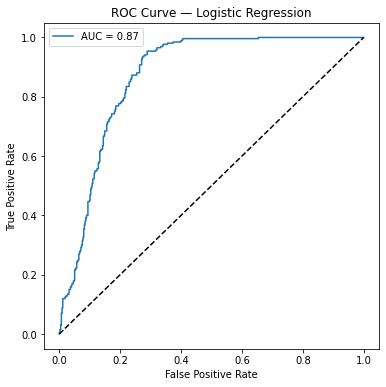

In [41]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_log, tpr_log, _ = roc_curve(y_test, y_pred_log)

plt.figure(figsize=(6,6))
plt.plot(fpr_log, tpr_log, label=f"AUC = {auc_log:.2f}")

plt.plot([0,1], [0,1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression")
plt.legend()

plt.show()

In [23]:
# Stack rasters
stack = np.stack([dem, slope, aspect, temp, ndvi_alps], axis=-1)

# Flatten
flat = stack.reshape(-1, 5)

# Create mask for valid pixels (no NaNs)
mask = ~np.isnan(flat).any(axis=1)

# Prepare output array
pred = np.zeros(flat.shape[0])

# Predict ONLY on valid pixels
pred[mask] = model.predict_proba(flat[mask])[:,1]

# Reshape back
prob_map = pred.reshape(dem.shape)
prob_map[~mask.reshape(dem.shape)] = np.nan

C:\Users\91702\anaconda3\lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


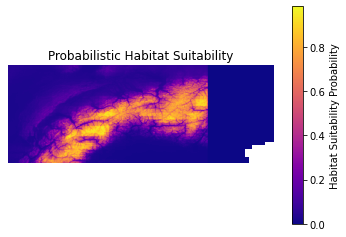

In [24]:
plt.imshow(prob_map, cmap="plasma")
plt.colorbar(label="Habitat Suitability Probability")
plt.title("Probabilistic Habitat Suitability")
plt.axis("off")
plt.show()

### Now let's move to Future Warming :  +2°C scenario

In [25]:
temp_future = temp + 2

In [26]:
stack_future = np.stack([dem, slope, aspect, temp_future, ndvi_alps], axis=-1)

flat_future = stack_future.reshape(-1, 5)

mask_future = ~np.isnan(flat_future).any(axis=1)

pred_future = np.zeros(flat_future.shape[0])
pred_future[mask_future] = model.predict_proba(flat_future[mask_future])[:,1]

prob_map_future = pred_future.reshape(dem.shape)

C:\Users\91702\anaconda3\lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


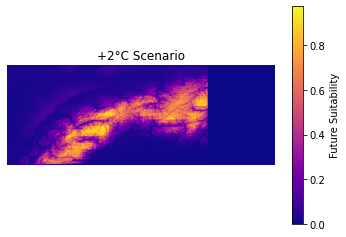

In [27]:
plt.imshow(prob_map_future, cmap="plasma")
plt.colorbar(label="Future Suitability")
plt.title("+2°C Scenario")
plt.axis("off")
plt.show()

### Habitat Loss

In [28]:
threshold = 0.5

baseline_bin = prob_map > threshold
future_bin = prob_map_future > threshold

baseline_area = baseline_bin.sum()
future_area = future_bin.sum()

print("Baseline area:", baseline_area)
print("Future area:", future_area)

Baseline area: 34821
Future area: 26519


In [29]:
# Habit loss
loss = baseline_area - future_area

print("Habitat loss:", loss)

Habitat loss: 8302


In [30]:
# Habitat Compression Index (HCI)
HCI = (baseline_area - future_area) / baseline_area

print("HCI:", HCI)

HCI: 0.23841934464834438


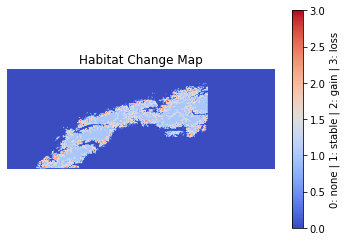

In [31]:
# visualizing the maps
loss_map = (baseline_bin == 1) & (future_bin == 0)
gain_map = (baseline_bin == 0) & (future_bin == 1)
stable_map = (baseline_bin == 1) & (future_bin == 1)

combined = np.zeros_like(baseline_bin, dtype=int)

combined[stable_map] = 1   # stable
combined[gain_map] = 2     # gain
combined[loss_map] = 3     # loss

plt.imshow(combined, cmap="coolwarm")

plt.title("Habitat Change Map")
plt.axis("off")

plt.colorbar(label="0: none | 1: stable | 2: gain | 3: loss")

plt.show()

### Under a +2°C warming scenario, Rock Ptarmigan habitat in the Swiss Alps is projected to decline by approximately 13%, indicating significant upward habitat compression.